# Mastering Model Generalization
## Customer Churn: Overfitting, Underfitting & Cross-Validation



We will use a synthetic customer-churn problem to make three ideas visible:

1. Overfitting — a model memorizes the training data.
2. Underfitting — a model is too simple.
3. Good generalization — a model balances complexity and performance.

Finally, we will use 5-fold cross-validation to get a more reliable estimate of model performance.


## 1. Setup

We use only NumPy, pandas, matplotlib and scikit-learn.

The dataset is synthetic, so the experiment is reproducible and we can deliberately include **three completely random noise features**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Reproducibility
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create a Synthetic Customer Churn Dataset

We create **400 customers**.

The useful features represent realistic churn signals:

- `support_calls` — frequent support calls can indicate dissatisfaction.
- `contract_type` — contract structure can influence churn.
- `monthly_charges` — pricing can influence churn.
- `tenure_months` — newer customers may be more likely to leave.

Then we deliberately add:

- `noise_1`
- `noise_2`
- `noise_3`

These three columns contain **no real information about churn**.

That gives our decision tree an opportunity to learn patterns that look useful in the training data but are actually random.

In [ ]:
# Number of customers
n = 400

# Predictive customer characteristics
support_calls = np.random.poisson(lam=2.2, size=n)
contract_type = np.random.choice([0, 1, 2], size=n, p=[0.45, 0.30, 0.25])
monthly_charges = np.random.normal(75, 20, size=n).clip(20, 130)
tenure_months = np.random.randint(1, 73, size=n)

# Completely random noise — intentionally unrelated to churn
noise_1 = np.random.normal(0, 1, size=n)
noise_2 = np.random.normal(0, 1, size=n)
noise_3 = np.random.normal(0, 1, size=n)

# Create a realistic-ish churn probability
logit = (
    -1.0
    + 0.38 * support_calls
    - 0.018 * tenure_months
    + 0.012 * (monthly_charges - 70)
    + 0.55 * (contract_type == 0)
    - 0.25 * (contract_type == 2)
)

probability = 1 / (1 + np.exp(-logit))
churn = np.random.binomial(1, probability)

df = pd.DataFrame({
    "support_calls": support_calls,
    "contract_type": contract_type,
    "monthly_charges": monthly_charges,
    "tenure_months": tenure_months,
    "noise_1": noise_1,
    "noise_2": noise_2,
    "noise_3": noise_3,
    "churn": churn
})

df.head()

,support_calls,contract_type,monthly_charges,tenure_months,noise_1,noise_2,noise_3,churn
0,4,1,93.381530,38,1.209266,0.096261,-0.411390,0
1,1,2,69.194509,15,-1.439564,-1.443890,-0.484050,0
2,3,2,80.347846,63,0.180583,0.173677,-1.256761,0
3,3,0,81.433956,21,0.145239,-0.701337,0.585491,0
4,1,1,61.638191,57,-0.619236,1.705643,-1.414976,0


In [ ]:
print("Dataset shape:", df.shape)
print("\nChurn distribution:")
print(df["churn"].value_counts(normalize=True).rename("proportion").round(3))

print("\nFeatures:")
print(df.columns.tolist())

Dataset shape: (400, 8)

Churn distribution:
churn
0    0.658
1    0.342
Name: proportion, dtype: float64

Features:
['support_calls', 'contract_type', 'monthly_charges', 'tenure_months', 'noise_1', 'noise_2', 'noise_3', 'churn']


### The trap

The first four columns contain information that can help predict churn.

The last three feature columns are **pure noise**.

A flexible model can still find patterns in those random columns — especially when it is allowed to keep splitting until it isolates individual training examples.

In [ ]:
X = df.drop(columns="churn")
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers :", len(X_test))

Training customers: 320
Testing customers : 80


# Scenario A — Overfitting

### Let the tree grow freely

An unconstrained decision tree can become extremely complex.

It may keep splitting until it has essentially **memorized the training customers**, including random noise.

The warning sign is:

> **Very high training performance + much lower test performance.**

This is the classic generalization problem.

In [ ]:
overfit_model = DecisionTreeClassifier(
    random_state=42
)

overfit_model.fit(X_train, y_train)

train_pred = overfit_model.predict(X_train)
test_pred = overfit_model.predict(X_test)

overfit_train = accuracy_score(y_train, train_pred)
overfit_test = accuracy_score(y_test, test_pred)

print(f"Training accuracy: {overfit_train:.2%}")
print(f"Testing accuracy : {overfit_test:.2%}")

Training accuracy: 100.00%
Testing accuracy : 50.00%


### What should we notice?

The important point is **not just the exact number**.

Look at the gap:

**Training accuracy − Testing accuracy**

A large gap tells us the model is fitting the training data much more closely than it is learning a pattern that transfers to unseen customers.

The random noise columns are part of the trap.

In [ ]:
overfit_gap = overfit_train - overfit_test

print(f"Generalization gap: {overfit_gap:.2%}")

Generalization gap: 50.00%


# Scenario B — Underfitting

Now we go to the opposite extreme.

We restrict the tree to **one split** using:

```python
max_depth=1
```

The model is now so simple that it cannot capture enough of the churn pattern.

This is **underfitting**:

> The model is too simple to learn the underlying relationship.

In [ ]:
underfit_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

underfit_model.fit(X_train, y_train)

under_train_pred = underfit_model.predict(X_train)
under_test_pred = underfit_model.predict(X_test)

underfit_train = accuracy_score(y_train, under_train_pred)
underfit_test = accuracy_score(y_test, under_test_pred)

print(f"Training accuracy: {underfit_train:.2%}")
print(f"Testing accuracy : {underfit_test:.2%}")

Training accuracy: 67.19%
Testing accuracy : 56.25%


### Underfitting pattern

Here the training score is already limited.

That is the clue:

- Training performance is not very high.
- Testing performance is also limited.
- There is not a huge train-test gap.

The model is not memorizing.

It simply **doesn't have enough flexibility**.

# Scenario C — The Sweet Spot

Now we add a little complexity back.

We use:

```python
max_depth=3
```

This gives the tree enough flexibility to learn meaningful churn patterns, while preventing it from becoming excessively complex.

In [ ]:
good_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

good_model.fit(X_train, y_train)

good_train_pred = good_model.predict(X_train)
good_test_pred = good_model.predict(X_test)

good_train = accuracy_score(y_train, good_train_pred)
good_test = accuracy_score(y_test, good_test_pred)

print(f"Training accuracy: {good_train:.2%}")
print(f"Testing accuracy : {good_test:.2%}")

Training accuracy: 73.75%
Testing accuracy : 56.25%


### This is what we want

The goal is **not** to maximize training accuracy.

The goal is to learn a pattern that continues to work on **customers the model has never seen before**.

So we want:

**Good training performance + good testing performance + a relatively small gap.**

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Underfitting", "Good Generalization", "Overfitting"],
    "Training Accuracy": [underfit_train, good_train, overfit_train],
    "Testing Accuracy": [underfit_test, good_test, overfit_test]
})

comparison["Gap"] = (
    comparison["Training Accuracy"]
    - comparison["Testing Accuracy"]
)

comparison.style.format({
    "Training Accuracy": "{:.2%}",
    "Testing Accuracy": "{:.2%}",
    "Gap": "{:.2%}"
})

,Model,Training Accuracy,Testing Accuracy,Gap
0,Underfitting,67.19%,56.25%,10.94%
1,Good Generalization,73.75%,56.25%,17.50%
2,Overfitting,100.00%,50.00%,50.00%


# Side-by-Side Comparison

The visualization makes the three situations easy to see:

- Underfitting: both scores are limited.
- Good generalization: training and testing stay relatively close.
- Overfitting: training shoots up while testing falls behind.

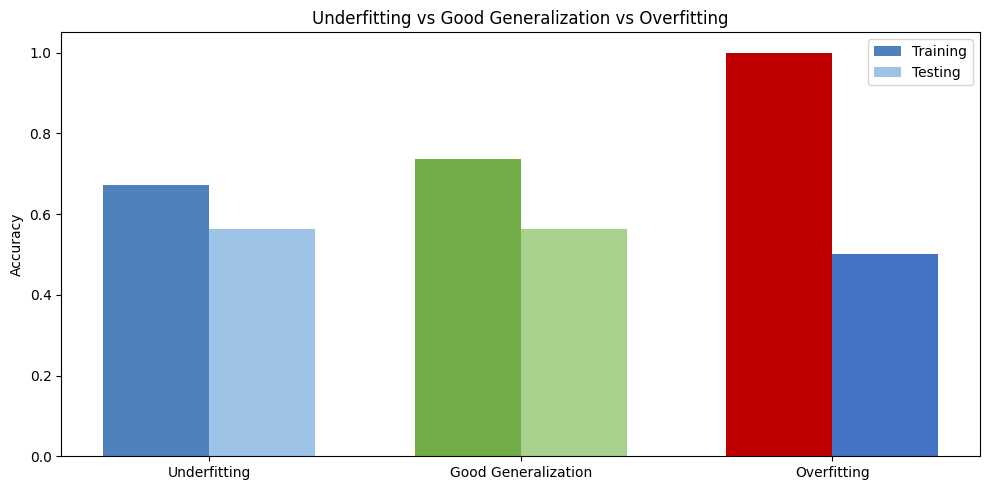

In [ ]:
labels = ["Underfitting", "Good Generalization", "Overfitting"]
train_scores = [underfit_train, good_train, overfit_train]
test_scores = [underfit_test, good_test, overfit_test]

x = np.arange(len(labels))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 5))

# Slide-inspired accent colors:
# blue = underfitting, green = good generalization,
# red/blue contrast = overfitting
bar_train = ax.bar(
    x - width/2,
    train_scores,
    width,
    label="Training",
    color=["#4F81BD", "#70AD47", "#C00000"]
)

bar_test = ax.bar(
    x + width/2,
    test_scores,
    width,
    label="Testing",
    color=["#9DC3E6", "#A9D18E", "#4472C4"]
)

ax.set_ylabel("Accuracy")
ax.set_title("Underfitting vs Good Generalization vs Overfitting")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.05)
ax.legend()

# ax.bar_label(bar_train, fmt="%.1f%%", padding=3)
# ax.bar_label(bar_test, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

# A Better Question: Can One Train/Test Split Mislead Us?

So far, we used **one train/test split**.

But what if that particular split was unusually easy — or unusually difficult?

Let's repeat the experiment with five different random splits.

This will show why we should not put too much confidence in one split.

In [ ]:
random_states = [7, 21, 42, 84, 100]
split_scores = []

for seed in random_states:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    model = DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    )

    model.fit(X_tr, y_tr)
    predictions = model.predict(X_te)

    score = accuracy_score(y_te, predictions)
    split_scores.append(score)

split_results = pd.DataFrame({
    "Random Split": random_states,
    "Test Accuracy": split_scores
})

split_results.style.format({
    "Test Accuracy": "{:.2%}"
})

,Random Split,Test Accuracy
0,7,61.25%
1,21,67.50%
2,42,56.25%
3,84,67.50%
4,100,72.50%


In [ ]:
print(f"Mean accuracy across these five splits: {np.mean(split_scores):.2%}")
print(f"Standard deviation: {np.std(split_scores, ddof=1):.2%}")

Mean accuracy across these five splits: 65.00%
Standard deviation: 6.31%


# 5-Fold Cross-Validation

Instead of manually creating several train/test splits, scikit-learn gives us a convenient tool:

`cross_val_score`

With **5-fold cross-validation**:

1. The data is divided into five folds.
2. The model trains on four folds.
3. It is evaluated on the remaining fold.
4. This repeats until every fold has been used as the validation set.
5. We get five scores instead of one.

In [ ]:
cv_scores = cross_val_score(
    good_model,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("5-fold CV scores:")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.2%}")

print(f"\nMean CV score: {cv_scores.mean():.2%}")
print(f"Standard deviation: {cv_scores.std(ddof=1):.2%}")

5-fold CV scores:
Fold 1: 67.50%
Fold 2: 67.50%
Fold 3: 57.50%
Fold 4: 61.25%
Fold 5: 61.25%

Mean CV score: 63.00%
Standard deviation: 4.38%


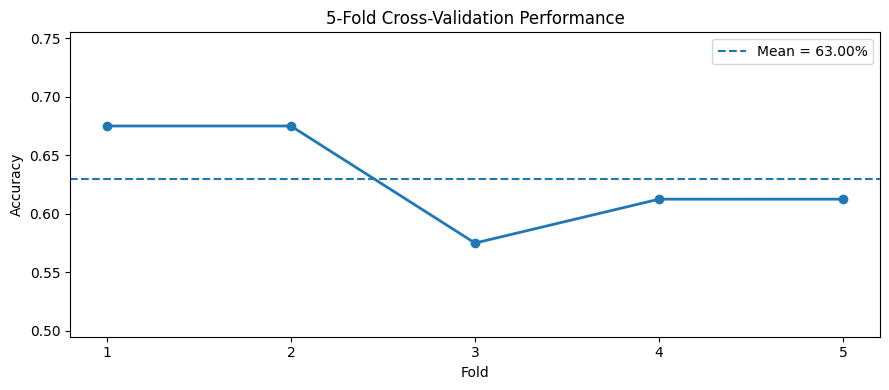

In [ ]:
plt.figure(figsize=(9, 4))

folds = np.arange(1, 6)

plt.plot(
    folds,
    cv_scores,
    marker="o",
    linewidth=2
)

plt.axhline(
    cv_scores.mean(),
    linestyle="--",
    label=f"Mean = {cv_scores.mean():.2%}"
)

plt.xticks(folds)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Performance")
plt.ylim(
    max(0, cv_scores.min() - 0.08),
    min(1, cv_scores.max() + 0.08)
)
plt.legend()

plt.tight_layout()
plt.show()

# Key Takeaways

### 1. Overfitting
A model can perform brilliantly on training data but fail to generalize.

### 2. Underfitting
A model that is too simple may perform poorly on both training and testing data.

### 3. Good Generalization
The sweet spot is a model that captures useful structure without memorizing the training data.

### 4. Cross-Validation
A single train/test split gives us one estimate.

Cross-validation gives us **multiple validation scores**, allowing us to examine the model's average performance and variability.

> **The objective is not the highest training score. The objective is reliable performance on unseen data.**

# Quick Quiz

Use the cells below during recording as interactive knowledge checks.

**Question 1**

A decision tree has 100% training accuracy but 68% testing accuracy. What is the most likely problem?

A. Underfitting  
B. Overfitting  
C. Perfect generalization  
D. Data visualization error

In [ ]:
from IPython.display import display, HTML

display(HTML("""
<button onclick="this.nextElementSibling.style.display='block'"
        style="font-size:16px;padding:10px 18px;">
Show Answer
</button>
<div style="display:none;margin-top:10px;">
<b>Answer: B — Overfitting.</b><br>
The model performs extremely well on training data but much worse on unseen data.
That large gap is a classic warning sign of overfitting.
</div>
"""))

**Question 2**

If we set `max_depth=1`, what are we deliberately doing?

A. Making the tree more complex  
B. Allowing the tree to memorize more noise  
C. Restricting model complexity  
D. Increasing the number of features

In [ ]:
display(HTML("""
<button onclick="this.nextElementSibling.style.display='block'"
        style="font-size:16px;padding:10px 18px;">
Show Answer
</button>
<div style="display:none;margin-top:10px;">
<b>Answer: C — Restricting model complexity.</b><br>
A depth-1 tree can make only one level of decision, so it may be too simple
to capture the underlying churn pattern.
</div>
"""))

**Question 3**

Why do we use cross-validation?

A. To make the training accuracy 100%  
B. To avoid evaluating the model  
C. To obtain a more reliable estimate of model performance  
D. To remove all noise features automatically

In [ ]:
display(HTML("""
<button onclick="this.nextElementSibling.style.display='block'"
        style="font-size:16px;padding:10px 18px;">
Show Answer
</button>
<div style="display:none;margin-top:10px;">
<b>Answer: C — To obtain a more reliable estimate of model performance.</b><br>
Cross-validation evaluates the model across multiple folds instead of relying
on a single train/test split.
</div>
"""))



We have controlled **model complexity**.

But there is another powerful question:

> **What if the problem isn't the model — what if the features themselves aren't good enough?**

In the next video, we'll look at **Feature Engineering**:

**How do we transform raw customer data into features that help a machine-learning model learn better?**

**See you in the next one! 🚀**